In [1]:
# napisanie regresji liniowej dla wielu wspolczunnikow minimalizujac funkcje bledu kwadtarowego
from typing import List
import random
import tqdm
def predict(x: List[float], beta: List[float]) -> float:
    "funkcja zwraca przewidywana wartosc na podstawie parametrow beta i warotsci x"
    " x = [1,_x1,x2,...,x_n+1] - wektor feature'row o dlugosci n + 1"
    " beta = [alpha, beta_1, beta_2,..,beta_n+1] wektor parametrow regresji liowej "
    return sum([x_i * b_i for x_i, b_i in zip(x,beta)])

assert predict([1,2,2], [0,1,1]) == 4

def error(x: List[float], y: float, beta: List[float]) -> float:
    "zwraca blad miedzy y a predykcja"
    return predict(x, beta) - y 
def sqr_error(x: List[float], y: float, beta: List[float]) -> float:
    "zwraca blad miedzy y a predykcja"
    err = error(x, y,beta )
    return err ** 2

def gradient(x: List[float], y: float, beta: List[float]) -> List[float]:
    "zwraca wektor pochodnych czastkowych policzonych z funkcji sqr_error wzgledem beta"
    return [2 * x_i * error(x,y,beta) for x_i in x]

def least_squares_fit(X: List[List[float]],
                      Y: List[float],
                      learning_rate: float = 0.001,
                      num_steps: int = 1000,
                      batch_size: int = 1) -> List[float]:
    
    beta = [random.uniform(0,1) for _ in range(len(X[0]))]
    
    for _ in range(num_steps):
        for start in range(0, len(X), batch_size):
            batch_x = X[start:start+batch_size]
            batch_y = Y[start:start+batch_size]
            
            batch_gradients = [gradient(x, y, beta) for x, y in zip(batch_x, batch_y)]            
            grad = [sum(col) / len(batch_x) for col in zip(*batch_gradients)]
            
            beta = [beta_i - learning_rate * grad_i for beta_i, grad_i in zip(beta, grad)]
    return beta


In [2]:
from typing import TypeVar, Callable
import numpy as np
X = TypeVar('X')          # Typ generyczny dla danych
Stat = TypeVar('Stat')    # Typ generyczny dla "statystyki"

def bootstrap_sample(data: List[X]) -> List[X]:
    """losowo wybiera len(data) elementów ze zwracaniem"""
    return [random.choice(data) for _ in data]

def bootstrap_statistic(data: List[X],
                        stats_fn: Callable[[List[X]], Stat],
                        num_samples: int) -> List[Stat]:
    """oblicza stats_fn na num_samples próbkach bootstrapowych z data"""
    return [stats_fn(bootstrap_sample(data)) for _ in tqdm.trange(num_samples)]

# 101 punktów, wszystkie bardzo bliskie 100
close_to_100 = [99.5 + random.random() for _ in range(101)]

# 101 punktów, 50 z nich blisko 0, 50 z nich blisko 200
far_from_100 = ([99.5 + random.random()] +
                [random.random() for _ in range(50)] +
                [200 + random.random() for _ in range(50)])

medians_close = bootstrap_statistic(close_to_100, np.mean, 100)
medians_far = bootstrap_statistic(far_from_100, np.mean, 100)
print(sorted(medians_close[:10]))
print(sorted(medians_far))

100%|██████████| 100/100 [00:00<00:00, 56588.02it/s]

[np.float64(99.97487336663842), np.float64(99.99433432626996), np.float64(99.9977230818209), np.float64(100.00600853107228), np.float64(100.01156087833706), np.float64(100.03300674075459), np.float64(100.03467251890825), np.float64(100.03811132047177), np.float64(100.04379299667059), np.float64(100.04810225127221)]
[np.float64(72.71948417633911), np.float64(77.68234048950136), np.float64(79.69099213423844), np.float64(81.62273190749843), np.float64(81.62879023612246), np.float64(81.65598128137114), np.float64(87.5624714634391), np.float64(87.58781026695772), np.float64(87.61185000925406), np.float64(87.6138566042625), np.float64(87.63601058594085), np.float64(88.61681083731678), np.float64(89.51967135899349), np.float64(89.64881518091212), np.float64(90.56511491910184), np.float64(91.54684889552058), np.float64(91.56906535346185), np.float64(92.51382680519255), np.float64(92.5168075781541), np.float64(92.54209926689798), np.float64(92.5433171896276), np.float64(92.5475034513324), np.fl

In [4]:
from typing import Tuple
import matplotlib.pyplot as plt
import math
def estimate_beta_sample(X: List[Tuple[List[float], float]]):
    "X to wektor zlaczony z x_i i y "
    x_sample = [x for x, _ in X]
    y_sample = [y for _, y in X]
    beta = least_squares_fit(x_sample, y_sample, num_steps=1000, batch_size=1, learning_rate=0.001)
    return beta

def coef_dist_bootstrap(xs: List[List[float]], ys: List[float], num_samples = 100):

    "zwraca rozlad kazdego wspolczynika regesji liniowej przy uzyciu metody bootstrap"
    "betas to maciez : wiersze to beta_i kazdej iteracji bootstrap, kolumny to rozklady beta_i "

    betas = bootstrap_statistic(data=list(zip(xs, ys)), stats_fn=estimate_beta_sample, num_samples=num_samples)
    array_betas = np.array(betas)
    num_betas = len(xs[0])
    num_rows_fig = math.ceil(num_betas/2)
    
    fig, ax = plt.subplots(num_rows_fig, 2, figsize=(10, 4 * num_rows_fig), squeeze=False)
    ax = ax.flatten() # Spłaszczamy tablicę osi do 1D dla łatwiejszej iteracji
    
    for i in range(num_betas):

        ax[i].hist(array_betas[:, i], bins=15, edgecolor='white', alpha=0.7)
        sigma = np.std(array_betas[:, i], ddof=1) 
        ax[i].set_title(f"Współczynnik $\\beta_{i}$ | SE: {sigma:.4f}")

    # Ukrywanie pustych osi, jeśli liczba współczynników jest nieparzysta
    for j in range(num_betas, len(ax)):
        fig.delaxes(ax[j])
        
    plt.tight_layout() 
    plt.show()
    return betas



100%|██████████| 100/100 [00:26<00:00,  3.80it/s]


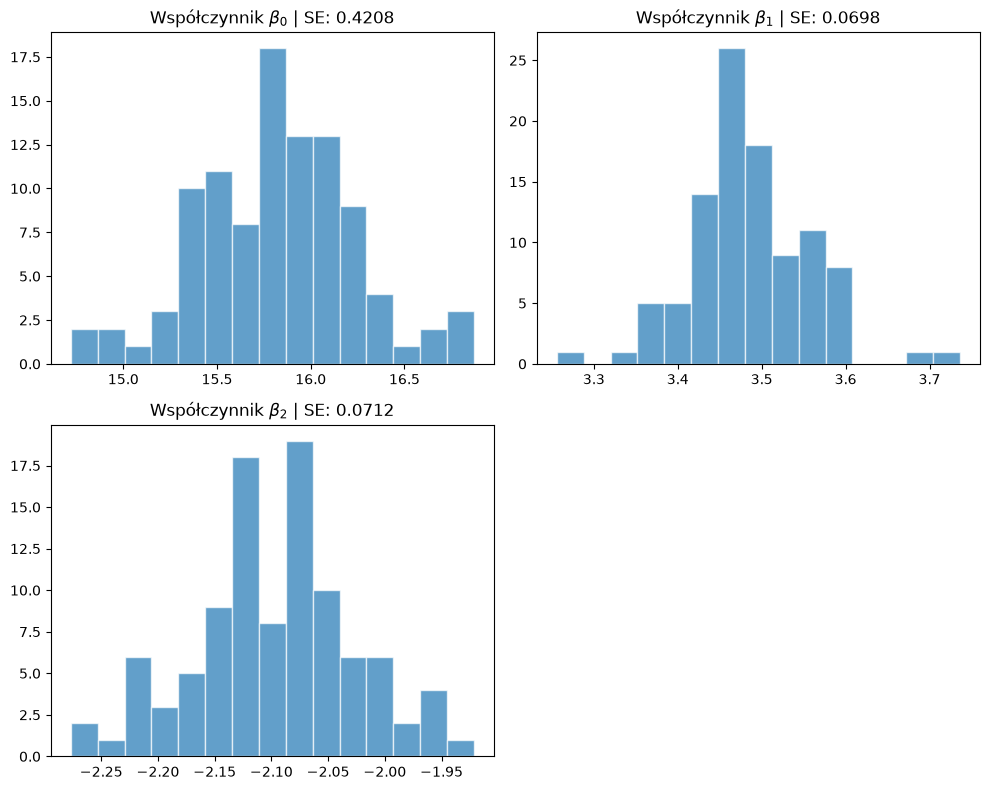

In [5]:
# 1. Zdefiniowanie prawdziwych współczynników modelu
TRUE_BETA_0 = 15.0  # Wyraz wolny (intercept)
TRUE_BETA_1 = 3.5   # Waga pierwszej cechy
TRUE_BETA_2 = -2.0  # Waga drugiej cechy
NOISE_STD = 2.0     # Poziom szumu (wpływa na szerokość rozkładu / błąd standardowy)

NUM_POINTS = 200

xs = []
ys = []

random.seed(67) 

for _ in range(NUM_POINTS):
    x1 = random.uniform(0, 10)
    x2 = random.uniform(0, 10)
    
    x_vector = [1.0, x1, x2]
    
    err = random.gauss(0, NOISE_STD)
    y = (TRUE_BETA_0 * 1.0) + (TRUE_BETA_1 * x1) + (TRUE_BETA_2 * x2) + err
    
    xs.append(x_vector)
    ys.append(y)


betas_rozkład = coef_dist_bootstrap(xs, ys, num_samples=100)

least_squares_fit: 100%|██████████| 1000/1000 [00:00<00:00, 2818.69it/s]


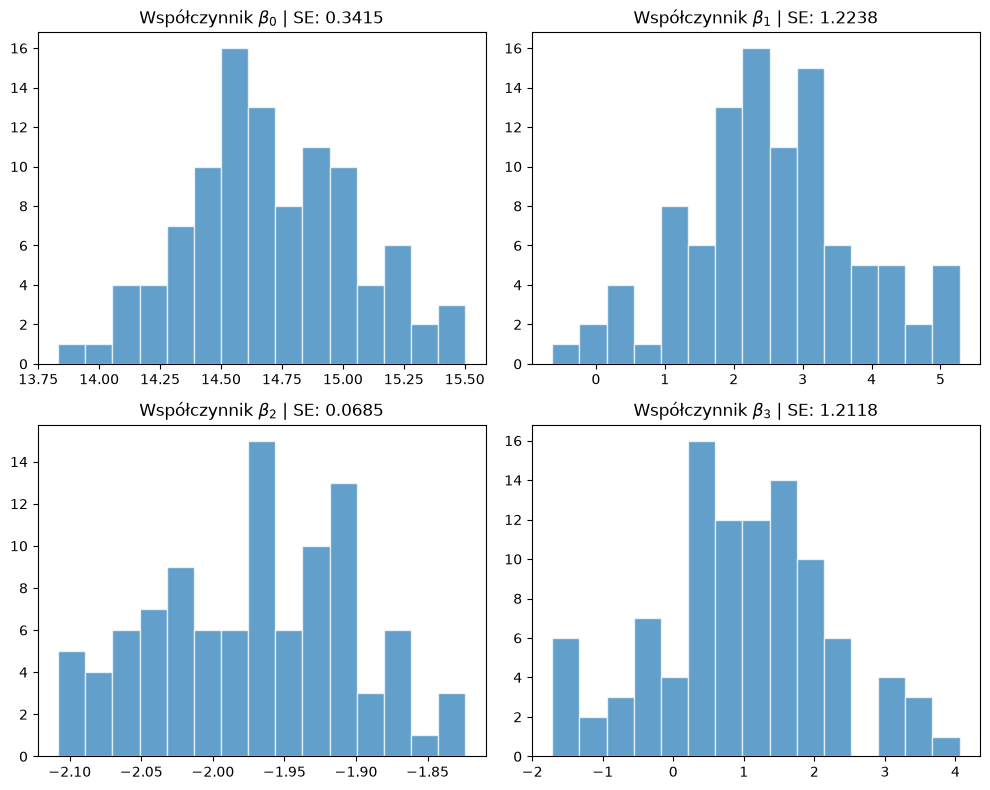

In [146]:
# 1. Zdefiniowanie prawdziwych współczynników modelu
TRUE_BETA_0 = 15.0  # Wyraz wolny (intercept)
TRUE_BETA_1 = 3.5   # Waga pierwszej cechy
TRUE_BETA_2 = -2.0  # Waga drugiej cechy
NOISE_STD = 2.0     # Poziom szumu (wpływa na szerokość rozkładu / błąd standardowy)

NUM_POINTS = 200

xs = []
ys = []

random.seed(67) 
for _ in range(NUM_POINTS):
    x1 = random.uniform(0, 10)
    x2 = random.uniform(0, 10)
    
    # Nowa, zbyteczna cecha x3 (silnie skorelowana z x1)
    x3 = x1 + random.gauss(0, 0.1)
    
    # Wektor wejściowy rozszerzony o x3
    x_vector = [1.0, x1, x2, x3]
    
    noise = random.gauss(0, NOISE_STD)
    
    #(TRUE_BETA_3 = 0)
    y = (TRUE_BETA_0 * 1.0) + (TRUE_BETA_1 * x1) + (TRUE_BETA_2 * x2) + noise
    
    xs.append(x_vector)
    ys.append(y)
betas_rozkład = coef_dist_bootstrap(xs, ys, num_samples=100)


In [ ]:
# mozemy testowac hipotezy statystyczne
# Zakładając, że beta_0 to indeks 1 w array_betas
rozklad_b0 = np.array(betas_rozkład)[:, 0]

dolna_granica = np.percentile(rozklad_b0, 2.5)
gorna_granica = np.percentile(rozklad_b0, 97.5)

print(f"95% Przedział ufności: [{dolna_granica:.4f}, {gorna_granica:.4f}], wartosc: {TRUE_BETA_0}")

95% Przedział ufności: [14.0978, 15.3650], wartosc: 15.0


In [154]:
import numpy as np
from scipy import stats

indeks_beta = 0       
wartosc_h0 = 15.0     


rozklad = np.array(betas_rozkład)[:, indeks_beta]
beta_mean = np.mean(rozklad)
se = np.std(rozklad, ddof=1)


t_stat = (beta_mean - wartosc_h0) / se


n = len(xs)
liczba_parametrow = len(xs[0])
df = n - liczba_parametrow 


p_value = 2 * (1 - stats.t.cdf(np.abs(t_stat), df))

print(f"Estymator (średnia rozkładu): {beta_mean:.4f}")
print(f"Błąd standardowy (SE):        {se:.4f}")
print(f"Statystyka t:                 {t_stat:.4f}")
print(f"p-value:                      {p_value:.4f}")
print("-" * 40)

if p_value < 0.05:
    print("Wynik: Odrzucamy H0 na poziomie istotności 0.05.")
    print("Testowana wartość statystycznie NIE pasuje do modelu.")
else:
    print("Wynik: Brak podstaw do odrzucenia H0.")
    print("Testowana wartość w pełni mieści się w granicach błędu modelu.")

Estymator (średnia rozkładu): 14.7031
Błąd standardowy (SE):        0.3415
Statystyka t:                 -0.8693
p-value:                      0.3857
----------------------------------------
Wynik: Brak podstaw do odrzucenia H0.
Testowana wartość w pełni mieści się w granicach błędu modelu.


In [ ]:
# ridge regularization

def ridge_penalty(beta: List[float], alpha: float) -> float:
    "wielkosc kary modelu za zbyt duze wartosci wag(pomijamy wyraz wolny beta[0])"
    return alpha * sum([b_i**2 for b_i in beta[1:]])

assert ridge_penalty([1,2], 0.5) == 2.0

def sqr_err_ridge(x: List[float], y: float, beta: List[float], alpha: float) -> float:
    "blad kwadradowy z dodana kara"
    return error(x,y,beta) ** 2 + ridge_penalty(beta, alpha)

def ridge_penalty_gradient(beta: List[float], alpha: float) -> List[float]:
    "pochodne czastkowe tylko dla ridge"
    return [0.] + [2* alpha * beta_i for beta_i in beta[1:]]

def sqr_ridge_gradient(x: List[float], y: float, beta: List[float], alpha: float) -> List[float]:
    "pochodne czastkowe dla calego bledu"
    return [x + y for x, y in zip(gradient(x,y,beta), ridge_penalty_gradient(beta, alpha))]

def least_squares_ridge_fit(X: List[List[float]],
                      Y: List[float],
                      learning_rate: float = 0.001,
                      num_steps: int = 1000,
                      alpha: float = 0.1,
                      batch_size: int = 1) -> List[float]:
    
    beta = [random.uniform(0,1) for _ in range(len(X[0]))]
    
    for _ in tqdm.trange(num_steps, desc="least_squares_fit"):
        for start in range(0, len(X), batch_size):
            batch_x = X[start:start+batch_size]
            batch_y = Y[start:start+batch_size]
            
            batch_gradients = [sqr_ridge_gradient(x, y, beta, alpha) for x, y in zip(batch_x, batch_y)]            
            grad = [sum(col) / len(batch_x) for col in zip(*batch_gradients)]
            
            beta = [beta_i - learning_rate * grad_i for beta_i, grad_i in zip(beta, grad)]
    return beta

In [179]:
# 1. Zdefiniowanie prawdziwych współczynników modelu
TRUE_BETA_0 = 15.0  # Wyraz wolny (intercept)
TRUE_BETA_1 = 3.5   # Waga pierwszej cechy
TRUE_BETA_2 = -2.0  # Waga drugiej cechy
NOISE_STD = 2.0     # Poziom szumu (wpływa na szerokość rozkładu / błąd standardowy)

NUM_POINTS = 200

xs = []
ys = []

random.seed(67) 
for _ in range(NUM_POINTS):
    x1 = random.uniform(0, 10)
    x2 = random.uniform(0, 10)
    
    # Nowa, zbyteczna cecha x3 (silnie skorelowana z x1)
    x3 = x1 + random.gauss(0, 0.1)
    
    # Wektor wejściowy rozszerzony o x3
    x_vector = [1.0, x1, x2, x3]
    
    noise = random.gauss(0, NOISE_STD)
    
    #(TRUE_BETA_3 = 0)
    y = (TRUE_BETA_0 * 1.0) + (TRUE_BETA_1 * x1) + (TRUE_BETA_2 * x2) + noise
    
    xs.append(x_vector)
    ys.append(y)
for alpha in [0, 0.01, 0.1, 0.5, 1, 5, 10, 25, 50]:
    print(least_squares_ridge_fit(xs, ys,learning_rate=0.001,num_steps=5000, batch_size=10, alpha=alpha), alpha)

least_squares_fit: 100%|██████████| 5000/5000 [00:01<00:00, 3046.33it/s]


[14.686813614461293, 2.315944938534253, -1.9596358263579396, 1.2370950008385166] 0


least_squares_fit: 100%|██████████| 5000/5000 [00:01<00:00, 3271.50it/s]


[14.682861180507526, 1.9974018606985415, -1.9569853207323926, 1.5535477314982604] 0.01


least_squares_fit: 100%|██████████| 5000/5000 [00:01<00:00, 3090.85it/s]


...

[16.008990498450565, 1.1032782701691086, -1.0007720212200524, 1.105544697552687] 10


least_squares_fit: 100%|██████████| 5000/5000 [00:01<00:00, 3310.11it/s]


[17.87326056947231, 0.6838728171659186, -0.6060594257593164, 0.6853807218184343] 25


least_squares_fit: 100%|██████████| 5000/5000 [00:01<00:00, 3296.52it/s]

[19.384346745762414, 0.39547361646194357, -0.38928182546465134, 0.39639188219143656] 50
